# 03 — Confident Learning QA

This notebook runs the actual QA pipeline: confident learning (`cleanlab`) to flag
likely-mislabeled images, two supporting rule-based checks (near-duplicate
detection, low-confidence outlier flagging), and loads everything into a SQLite
database with a real schema — the recordkeeping layer notebook 04's SQL analysis
runs against.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data_loading as dl
from src import qa
from src import db

sns.set_theme(style="whitegrid")
CACHE_DIR = PROJECT_ROOT / "data" / "cache"

master_df = pd.read_parquet(CACHE_DIR / "master_df.parquet")
embeddings = np.load(CACHE_DIR / "embeddings.npy")
pred_probs = np.load(CACHE_DIR / "pred_probs.npy")
labels = master_df["true_label"].to_numpy()
print(master_df.shape, embeddings.shape, pred_probs.shape)

(60000, 10) (60000, 1280) (60000, 10)


## Run confident learning

In [2]:
issue_mask, quality_scores = qa.find_label_issues(labels, pred_probs)
n_flagged = int(issue_mask.sum())
print(f"confident learning flagged {n_flagged} / {len(issue_mask)} images "
      f"({n_flagged/len(issue_mask)*100:.2f}%) as likely mislabeled")

confident learning flagged 6439 / 60000 images (10.73%) as likely mislabeled


In [3]:
qa_df = qa.build_qa_table(master_df, pred_probs, issue_mask, quality_scores)
qa_df["predicted_label_name"] = qa_df["predicted_label"].map(lambda i: dl.CLASS_NAMES[i])
qa_df[["global_id", "split", "true_label_name", "predicted_label_name", "pred_prob_true_label", "margin", "cl_flagged"]].head()

,global_id,split,true_label_name,predicted_label_name,pred_prob_true_label,margin,cl_flagged
0,0,train,frog,frog,0.999048,0.0,False
1,1,train,truck,truck,1.000000,0.0,False
2,2,train,truck,truck,0.999976,0.0,False
3,3,train,deer,deer,0.999929,0.0,False
4,4,train,automobile,automobile,1.000000,0.0,False


## Rule-based check #1: which classes get flagged most?

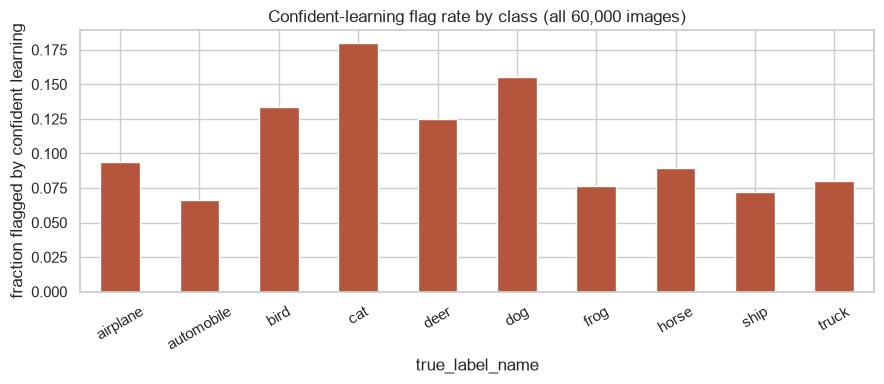

true_label_name
cat           0.180000
dog           0.155500
bird          0.133667
deer          0.125167
airplane      0.093500
horse         0.089833
truck         0.080167
frog          0.076500
ship          0.072167
automobile    0.066667
Name: cl_flagged, dtype: float64

In [4]:
flag_rate_by_class = (
    qa_df.groupby("true_label_name")["cl_flagged"].mean().reindex(dl.CLASS_NAMES)
)
fig, ax = plt.subplots(figsize=(9, 4))
flag_rate_by_class.plot(kind="bar", ax=ax, color="#b5563c")
ax.set_ylabel("fraction flagged by confident learning")
ax.set_title("Confident-learning flag rate by class (all 60,000 images)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "03_flag_rate_by_class.png", dpi=150)
plt.show()
flag_rate_by_class.sort_values(ascending=False)

One of this project's hypotheses is that visually-confusable classes (cat/dog,
automobile/truck) show disproportionately higher flag rates than visually distinct
ones. The chart above is the first look; notebook 04 checks this more rigorously
against the *validated* (ground-truth-confirmed) errors specifically, not just raw
CL flags, since CL flags alone could just reflect embedding-quality noise rather
than real label problems.

## Rule-based check #2: near-duplicate images

In [5]:
dup_df = qa.detect_near_duplicates(embeddings, labels, qa_df["global_id"].to_numpy(), threshold=0.995)
print(f"near-duplicate pairs found (cosine similarity >= 0.995, same class): {len(dup_df)}")
dup_df.sort_values('cosine_similarity', ascending=False).head(10)

near-duplicate pairs found (cosine similarity >= 0.995, same class): 0


,global_id_a,global_id_b,class_label,cosine_similarity


In [6]:
if len(dup_df):
    top = dup_df.sort_values("cosine_similarity", ascending=False).iloc[0]
    id_a, id_b = int(top["global_id_a"]), int(top["global_id_b"])

    def get_row_image(global_id):
        row = qa_df.loc[qa_df["global_id"] == global_id].iloc[0]
        ds = train_ds if row["split"] == "train" else test_ds
        return dl.get_image_array(ds, int(row["split_index"])), row

    train_ds, test_ds = dl.load_cifar10()
    img_a, row_a = get_row_image(id_a)
    img_b, row_b = get_row_image(id_b)

    fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
    axes[0].imshow(img_a); axes[0].set_title(f"id {id_a} ({row_a['true_label_name']})"); axes[0].axis("off")
    axes[1].imshow(img_b); axes[1].set_title(f"id {id_b} ({row_b['true_label_name']})"); axes[1].axis("off")
    plt.suptitle(f"Highest-similarity near-duplicate pair (cosine={top['cosine_similarity']:.4f})")
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "reports" / "figures" / "03_top_near_duplicate.png", dpi=150)
    plt.show()
else:
    print("No near-duplicate pairs found at this threshold.")

No near-duplicate pairs found at this threshold.


## Rule-based check #3: low-confidence outliers (independent of the CL flag)

In [7]:
low_conf_threshold = 0.3
low_conf_mask = qa_df["pred_prob_max"] < low_conf_threshold
print(f"images where the model's own top prediction has probability < {low_conf_threshold}: "
      f"{low_conf_mask.sum()} ({low_conf_mask.mean()*100:.2f}%)")

overlap = (low_conf_mask & qa_df["cl_flagged"]).sum()
print(f"overlap with CL-flagged: {overlap} / {low_conf_mask.sum()} low-confidence images "
      f"are also CL-flagged ({overlap / max(low_conf_mask.sum(),1) * 100:.1f}%)")
print(f"low-confidence but NOT CL-flagged: {(low_conf_mask & ~qa_df['cl_flagged']).sum()} "
      "-- these read as generically hard/ambiguous images rather than likely mislabels.")

images where the model's own top prediction has probability < 0.3: 30 (0.05%)
overlap with CL-flagged: 0 / 30 low-confidence images are also CL-flagged (0.0%)
low-confidence but NOT CL-flagged: 30 -- these read as generically hard/ambiguous images rather than likely mislabels.


## Build the prioritized review queue

In [8]:
dup_ids = set(dup_df["global_id_a"]).union(set(dup_df["global_id_b"])) if len(dup_df) else set()
queue_df = qa.build_review_queue(qa_df, dup_ids)
print(f"review queue size: {len(queue_df)}")
print(queue_df["review_category"].value_counts())
queue_df[["review_priority", "global_id", "split", "true_label_name", "predicted_label_name", "margin", "review_category"]].head(15)

review queue size: 6439
review_category
likely_mislabel    6439
Name: count, dtype: int64


,review_priority,global_id,split,true_label_name,predicted_label_name,margin,review_category
0,1,28688,train,automobile,truck,1.000000,likely_mislabel
1,2,53450,test,truck,automobile,1.000000,likely_mislabel
2,3,13207,train,automobile,truck,1.000000,likely_mislabel
3,4,25048,train,automobile,truck,1.000000,likely_mislabel
4,5,39335,train,ship,automobile,1.000000,likely_mislabel
5,6,55806,test,airplane,ship,1.000000,likely_mislabel
6,7,53560,test,automobile,truck,1.000000,likely_mislabel
7,8,43731,train,airplane,ship,1.000000,likely_mislabel
8,9,8200,train,airplane,ship,1.000000,likely_mislabel
9,10,4455,train,bird,airplane,1.000000,likely_mislabel


## Load everything into SQLite

In [9]:
db_path = PROJECT_ROOT / "data" / "label_quality.db"
conn = db.get_connection(db_path)
db.load_images(conn, qa_df)
db.load_review_queue(conn, queue_df)
db.load_near_duplicates(conn, dup_df)

n_images = conn.execute("SELECT COUNT(*) FROM images").fetchone()[0]
n_queue = conn.execute("SELECT COUNT(*) FROM review_queue").fetchone()[0]
n_dups = conn.execute("SELECT COUNT(*) FROM near_duplicates").fetchone()[0]
print(f"images table: {n_images} rows")
print(f"review_queue table: {n_queue} rows")
print(f"near_duplicates table: {n_dups} rows")
assert n_images == 60000
assert n_queue == n_flagged
conn.close()

images table: 60000 rows
review_queue table: 6439 rows
near_duplicates table: 0 rows


## Handoff to notebook 04

`data/label_quality.db` now holds the full per-image record set, the prioritized
review queue, and the near-duplicate pairs. Notebook 04 queries this database
directly with SQL to answer the project's central question: does this QA process
actually catch the real, human-confirmed label errors?